# Junior Data Analyst: data analysis and anomaly detection in part images

**Background:** parts are photographed at the end of production and a human inspector labelled some images as
OK (0) or defective (1). Alerts went up recently, and it is unclear whether the cause is **part quality**,
**imaging conditions**, or **the data/labels themselves**.

**Goal:** explore the data and images, build a simple and explainable first-pass detector for suspicious images,
validate it honestly, and draw conclusions.

**How to run:** from this folder, *Run All* (or `jupyter nbconvert --to notebook --execute --inplace solution.ipynb`).
Needs numpy, pandas, opencv-python, matplotlib and scikit-learn; runs on a CPU in under a minute.

In [1]:
from pathlib import Path
import cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(".")
SEED = 42
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

def read_gray(rel_path):
    # cv2.imread fails on Windows paths with non-ASCII characters (e.g. a Hebrew folder name),
    # so read the bytes with numpy and decode them with OpenCV.
    return cv2.imdecode(np.fromfile(str(DATA_DIR / rel_path), np.uint8), cv2.IMREAD_GRAYSCALE)

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("train:", train.shape, " test:", test.shape)
display(train.head())

train: (168, 10)  test: (72, 8)


,image_id,file,batch,line,camera,shift,timestamp_utc,exposure_setting,inspector_label,inspector_type
0,IMG_0004,images/IMG_0004.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T07:45:00Z,NORMAL,1,stain
1,IMG_0005,images/IMG_0005.jpg,BATCH-A,LINE-1,CAM-B,DAY,2026-11-02T08:00:00Z,LOW,0,none
2,IMG_0006,images/IMG_0006.jpg,BATCH-A,LINE-1,CAM-A,DAY,2026-11-02T08:15:00Z,NORMAL,1,stain
3,IMG_0007,images/IMG_0007.jpg,BATCH-A,LINE-1,CAM-B,NIGHT,2026-11-02T08:30:00Z,LOW,1,stain
4,IMG_0008,images/IMG_0008.jpg,BATCH-A,LINE-2,CAM-B,DAY,2026-11-02T08:45:00Z,NORMAL,0,none


## Part A: getting to know the data

### Data quality checks
Before any analysis: missing values, duplicate IDs, overlap between train and test, and whether every image file exists.

In [2]:
checks = {
    "missing values (train)": int(train.isna().sum().sum()),
    "missing values (test)": int(test.isna().sum().sum()),
    "duplicate image_id (train)": int(train.image_id.duplicated().sum()),
    "image_id in both train and test": len(set(train.image_id) & set(test.image_id)),
    "image files missing on disk": int(sum(not (DATA_DIR / f).exists() for f in pd.concat([train.file, test.file]))),
    "image files in images/": len(list((DATA_DIR / "images").glob("*.jpg"))),
}
display(pd.Series(checks, name="value").to_frame())
print("columns only in train:", sorted(set(train.columns) - set(test.columns)))

,value
missing values (train),0
missing values (test),0
duplicate image_id (train),0
image_id in both train and test,0
image files missing on disk,0
image files in images/,240


columns only in train: ['inspector_label', 'inspector_type']


The data is clean. Two columns exist only in train: `inspector_label` (the target) and `inspector_type`.

**Leakage trap:** `inspector_type` is the inspector's defect type, and it maps exactly onto the label
(`none` = 0, every other type = 1). It is not available for test images, so it must **never** be used as a model feature.
It is used here only to *understand* the data.

In [3]:
display(pd.crosstab(train.inspector_type, train.inspector_label, margins=True))

inspector_label,0,1,All
inspector_type,,,
edge_chip,0,14,14
missing_hole,0,9,9
none,112,0,112
scratch,0,13,13
stain,0,20,20
All,112,56,168


### A1. Number of records and label distribution

In [4]:
lab = train.inspector_label.map({0: "OK (0)", 1: "defective (1)"})
dist = pd.DataFrame({"count": lab.value_counts(), "share_%": (100 * lab.value_counts(normalize=True)).round(1)})
print(f"Labelled records: {len(train)}   |   Test records (unlabelled): {len(test)}")
display(dist)

Labelled records: 168   |   Test records (unlabelled): 72


,count,share_%
inspector_label,,
OK (0),112,66.7
defective (1),56,33.3


Two thirds of the labelled images are OK and one third is defective. The classes are imbalanced but not extremely,
so accuracy alone would be misleading (predicting "OK" for everything already gives 67 %). Precision and recall are reported in Part D.

### A2. Defect rate per camera (with number of images)

In [5]:
by_cam = (train.groupby("camera").inspector_label
               .agg(n_images="size", n_defective="sum", defect_rate="mean"))
by_cam["defect_rate_%"] = (100 * by_cam.pop("defect_rate")).round(1)
display(by_cam)

# Is a ~4-point difference meaningful with n=95 vs n=73? Rough 95% CI for each proportion:
for cam, r in by_cam.iterrows():
    p, n = r["defect_rate_%"] / 100, r.n_images
    half = 1.96 * np.sqrt(p * (1 - p) / n) * 100
    print(f"{cam}: {100*p:.1f}% ± {half:.1f} pts (95% CI)")

,n_images,n_defective,defect_rate_%
camera,,,
CAM-A,95,30,31.6
CAM-B,73,26,35.6


CAM-A: 31.6% ± 9.3 pts (95% CI)
CAM-B: 35.6% ± 11.0 pts (95% CI)


The defect rate is about the same for both cameras (31.6 % vs 35.6 %), and the confidence intervals (about ±10 points) overlap heavily.
**On their own labels, the cameras do not explain the alerts.**

The other metadata looks the same: every group is in the 30–38 % range. Batch is the only field with a wider spread:

In [6]:
rows = []
for col in ["camera", "line", "shift", "exposure_setting", "batch"]:
    g = train.groupby(col).inspector_label.agg(["size", "mean"])
    for k, r in g.iterrows():
        rows.append({"field": col, "value": k, "n": int(r["size"]), "defect_rate_%": round(100 * r["mean"], 1)})
display(pd.DataFrame(rows).set_index(["field", "value"]))
print("Camera x exposure (counts): LOW exposure exists only on CAM-B, so the two are confounded")
display(pd.crosstab(train.camera, train.exposure_setting))

n  defect_rate_%
field            value                     
camera           CAM-A    95           31.6
                 CAM-B    73           35.6
line             LINE-1   88           33.0
                 LINE-2   80           33.8
shift            DAY      82           31.7
                 NIGHT    86           34.9
exposure_setting AUTO     80           30.0
                 LOW      48           37.5
                 NORMAL   40           35.0
batch            BATCH-A  42           33.3
                 BATCH-B  42           26.2
                 BATCH-C  42           42.9
                 BATCH-D  42           31.0

Camera x exposure (counts): LOW exposure exists only on CAM-B, so the two are confounded


exposure_setting,AUTO,LOW,NORMAL
camera,,,
CAM-A,65,0,30
CAM-B,15,48,10


### A3. One chart, one insight: what kind of defect does each batch get?

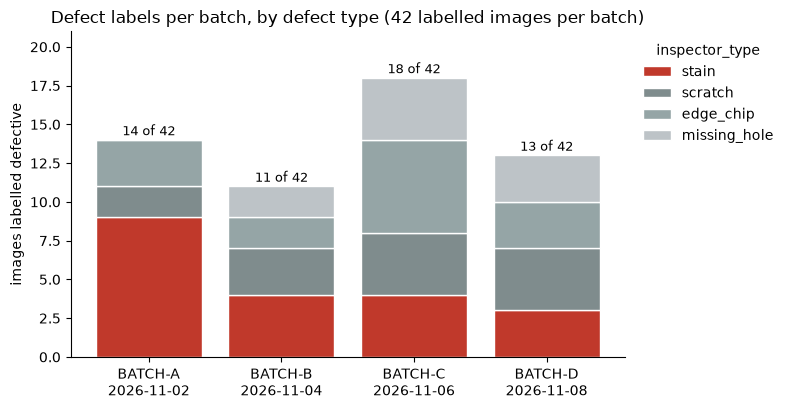

inspector_type,stain,scratch,edge_chip,missing_hole,total
batch,,,,,
BATCH-A,9,2,3,0,14
BATCH-B,4,3,2,2,11
BATCH-C,4,4,6,4,18
BATCH-D,3,4,3,3,13


In [7]:
types = ["stain", "scratch", "edge_chip", "missing_hole"]
ct = pd.crosstab(train.batch, train.inspector_type)[types]
day = train.groupby("batch").timestamp_utc.first().str[:10]

fig, ax = plt.subplots(figsize=(8, 4.2))
bottom = np.zeros(len(ct))
colors = {"stain": "#c0392b", "scratch": "#7f8c8d", "edge_chip": "#95a5a6", "missing_hole": "#bdc3c7"}
for t in types:
    ax.bar(ct.index, ct[t], bottom=bottom, color=colors[t], label=t, edgecolor="white")
    bottom += ct[t].values
for i, (b, tot) in enumerate(zip(ct.index, bottom)):
    ax.text(i, tot + 0.3, f"{int(tot)} of 42", ha="center", fontsize=9)
ax.set_xticks(range(len(ct)), [f"{b}\n{day[b]}" for b in ct.index])
ax.set_ylabel("images labelled defective"); ax.set_ylim(0, bottom.max() + 3)
ax.set_title("Defect labels per batch, by defect type (42 labelled images per batch)")
ax.legend(title="inspector_type", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()
display(ct.assign(total=ct.sum(axis=1)))

**Insight:** scratches, edge chips and missing holes are stable across batches (2–6 each). **Stains** are the outlier:
batch A (Nov 2) has **9 stain labels**, against 3–4 in every other batch.

A sudden spike in a single defect type, on a single day, while the other types stay flat, has two possible explanations:
a real (temporary) stain problem in production, or **labelling drift**, meaning the inspector marked stains more readily that day.
The metadata alone can't tell these apart, but the images can. This is checked in Part B by looking at the batch A stain images
and comparing them with an image-based anomaly score.